# Polynomial Regression

## Fit a polynomial to a given data set

In this example for the given dataset, the polynomial fitted is of the form
$$ h_\theta (x) = \theta_0 + \theta_1 x + \theta_2 x^2 + \theta_3 x^3 $$

Reference: https://towardsdatascience.com/

### Step 1: Import libraries and dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Importing the dataset
#dataset = pd.read_csv('https://s3.us-west-2.amazonaws.com/public.gamelab.fun/dataset/position_salaries.csv')

dataset = pd.read_csv('position_salaries.csv')
# change the file path accordingly

X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values

In [2]:
print(type(dataset))
print(X.shape)
print(y.shape)
dataset.head()

<class 'pandas.core.frame.DataFrame'>
(10, 1)
(10,)


,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


### Step 2: Prepare and visualize the given data set

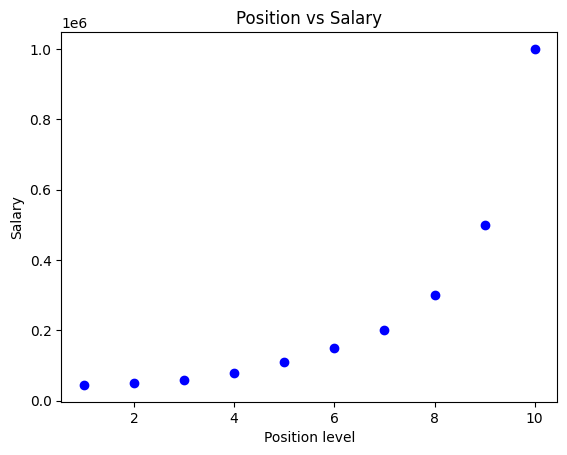

In [3]:
plt.scatter(X,y, color = 'blue')
plt.title('Position vs Salary')
plt.xlabel('Position level')
plt.ylabel('Salary')
plt.show()

### Step 3: Create and train the machine learning model

In [4]:
# Fitting Polynomial Regression to the dataset
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

poly_reg = PolynomialFeatures(degree=3) # eqn of deg 3
X_poly = poly_reg.fit_transform(X) # x is of deg 3

pol_reg = LinearRegression()
pol_reg.fit(X_poly, y)

LinearRegression()

### Step 4: Visualize the results

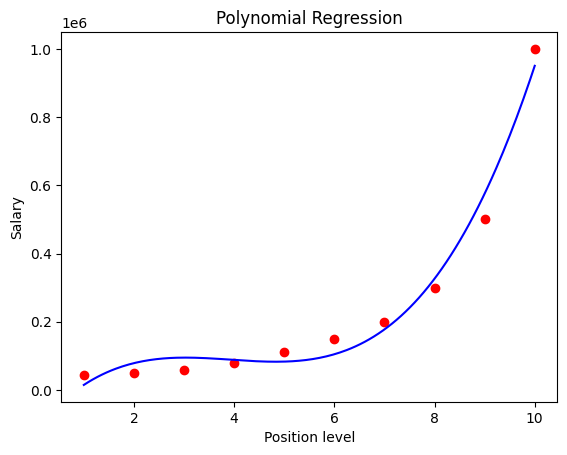

In [5]:
# Visualizing the Polynomial Regression results
# evaluate on a fine grid so the cubic CURVE is visible (not just a line joining the 10 data points)
X_grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, pol_reg.predict(poly_reg.transform(X_grid)), color='blue')
plt.title('Polynomial Regression')
plt.xlabel('Position level')
plt.ylabel('Salary')
plt.show()
# with few datapoints, a higher degree fits them better in-sample but overfits (try degree=6..9)

### Step 5: Prediction

In [6]:
# predict the values for the given dataset X
# (transform, not fit_transform: the polynomial features were already fitted in Step 3)
Y_pred = pol_reg.predict(poly_reg.transform(X))

### Step 6: Performance measures

In [7]:
from sklearn.metrics import mean_squared_error, r2_score
# NOTE: the model is trained and evaluated on the same 10 points (no train/test split),
# so these are IN-SAMPLE measures; they say nothing about generalisation.
# The mean squared error
print("Mean squared error = %.2f" % mean_squared_error(y, Y_pred))
# R^2 score: 1 is perfect prediction
print('R2 score = %.2f' % r2_score(y, Y_pred))

Mean squared error = 1515662004.66
R2 score = 0.98
